---
title: ""
format:
  pdf:
    documentclass: article
    pdf-engine: xelatex
    fontsize: 12pt
    mainfont: Times New Roman
    mathfont: Cambria Math
    monofont: Courier New
    papersize: letter
    geometry: margin=1in
    toc: false
    number-sections: false
    colorlinks: false
    keep-tex: false
    include-in-header:
      text: |
        \usepackage{fvextra}
        \fvset{fontsize=\footnotesize,breaklines=true}
        \usepackage{caption}
        \captionsetup{font=normalsize}
        \raggedbottom
execute:
  echo: false
  warning: false
  error: false
jupyter: ir
---

In [1]:
#| include: false
# Setup: packages and display options
library(tidyverse)
library(broom)
library(SkewHyperbolic)
options(width = 64, repr.plot.res = 180)

# Helper: print a small data frame as a table in the report
report_table <- function(data, caption) {
  header <- paste(names(data), collapse = " | ")
  rule <- paste(rep("---", ncol(data)), collapse = " | ")
  rows <- apply(data, 1, paste, collapse = " | ")
  markdown <- paste(c(paste0("**", caption, "**"), "",
    paste0("| ", header, " |"), paste0("| ", rule, " |"),
    paste0("| ", rows, " |")), collapse = "\n")
  IRdisplay::display_markdown(markdown)
}

-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.2.0
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.3     v tibble    3.3.1
v lubridate 1.9.5     v tidyr     1.3.2
v purrr     1.2.2     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
#| include: false
# Data: the 202 athletes in the ais data frame. Keep the 28 men who
# row or swim.
data(ais, package = "SkewHyperbolic")
dat <- ais %>%
  filter(sex == "male", sport %in% c("Row", "Swim")) %>%
  droplevels()
stopifnot(nrow(dat) == 28, !anyNA(dat),
  levels(dat$sport) == c("Row", "Swim"))

# Body fat percentage of each group
bf_row <- dat %>% filter(sport == "Row") %>% pull(Bfat)
bf_swim <- dat %>% filter(sport == "Swim") %>% pull(Bfat)

In [3]:
#| include: false
# Summary statistics for each sport (Table 1)
descriptive <- dat %>%
  group_by(sport) %>%
  summarize(N = n(), Mean = mean(Bfat), SD = sd(Bfat),
    Median = median(Bfat), IQR = IQR(Bfat),
    Min = min(Bfat), Max = max(Bfat)) %>%
  rename(Sport = sport)

# Difference in sample means, Row minus Swim
observed_diff <- mean(bf_row) - mean(bf_swim)

In [4]:
#| include: false
# Welch two-sample t-test and Wilcoxon rank-sum test (both two-sided)
welch <- t.test(Bfat ~ sport, data = dat)
wilcox <- wilcox.test(Bfat ~ sport, data = dat)

# tidy() turns each test result into a one-row table
welch_tidy <- tidy(welch)
wilcox_tidy <- tidy(wilcox)

# Rank-sum quantities quoted in Section 3.2
row_rank_sum <- dat %>%
  mutate(bfat_rank = rank(Bfat)) %>%
  filter(sport == "Row") %>%
  summarize(total = sum(bfat_rank)) %>%
  pull(total)
expected_rank_sum <- 15 * (28 + 1) / 2
prob_row_higher <- wilcox_tidy$statistic / (15 * 13)

In [5]:
#| include: false
# Permutation test, following the steps in the lecture slides.
# There are about 37 million ways to split the 28 values into groups
# of 15 and 13, so we use a random sample of 49,999 of them.
set.seed(20261114)
n_perm <- 49999

permuted_diff <- replicate(n_perm, {
  # Rearrange the 28 values, split them into 15 and 13, and
  # compute T, the difference in the two sample means
  shuffled <- sample(dat$Bfat)
  mean(shuffled[dat$sport == "Row"]) -
    mean(shuffled[dat$sport == "Swim"])
})

# Count the rearrangements at least as extreme as the observed one.
# The +1 counts the observed arrangement itself.
extremes <- sum(abs(permuted_diff) >= abs(observed_diff))
perm_p <- (extremes + 1) / (n_perm + 1)
perm_se <- sqrt(perm_p * (1 - perm_p) / (n_perm + 1))

permutation <- data.frame(observed_diff, n_perm, seed = 20261114,
  possible_splits = choose(28, 15), extremes,
  p_value = perm_p, monte_carlo_se = perm_se)

In [6]:
#| include: false
# Checks used in Section 3.5
shapiro_row <- shapiro.test(bf_row)
shapiro_swim <- shapiro.test(bf_swim)
variance_test <- var.test(Bfat ~ sport, data = dat)
sd_ratio <- sd(bf_row) / sd(bf_swim)

# Values beyond the boxplot whiskers (marked in Figure 1)
outliers <- dat %>%
  group_by(sport) %>%
  filter(Bfat %in% boxplot.stats(Bfat)$out) %>%
  ungroup() %>%
  select(sport, Bfat) %>%
  arrange(sport, Bfat) %>%
  as.data.frame()

\thispagestyle{empty}

# Body Fat Percentage of Male Rowers and Male Swimmers at the Australian Institute of Sport

**STAT300 Data Analysis Project**

**Group leader** [Leader name]

| Name | Student ID | contribution |
|:-----|:-----------|:--------------------|
| [Member 1] | [Student ID] |  contribution] |
| [Member 2] | [Student ID] |  contribution] |
| [Member 3] | [Student ID] |  contribution] |

**Abstract**

[]

**AI use**

[]

\newpage

\setcounter{table}{0}

\pagenumbering{arabic}

## 1. Introduction

## 2. Data description and exploratory analysis

In [7]:
#| echo: false
# Table 1: round the summary statistics and print them as a table
table1 <- descriptive %>%
  mutate(across(Mean:Max, ~ sprintf("%.2f", .x)))
report_table(table1,
  "Table 1. Body fat percentage (%) by sport, male athletes.")

**Table 1. Body fat percentage (%) by sport, male athletes.**

| Sport | N | Mean | SD | Median | IQR | Min | Max |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Row | 15 | 9.41 | 1.56 | 9.36 | 1.13 | 6.96 | 12.61 |
| Swim | 13 | 8.30 | 1.48 | 8.47 | 1.98 | 6.16 | 11.72 |

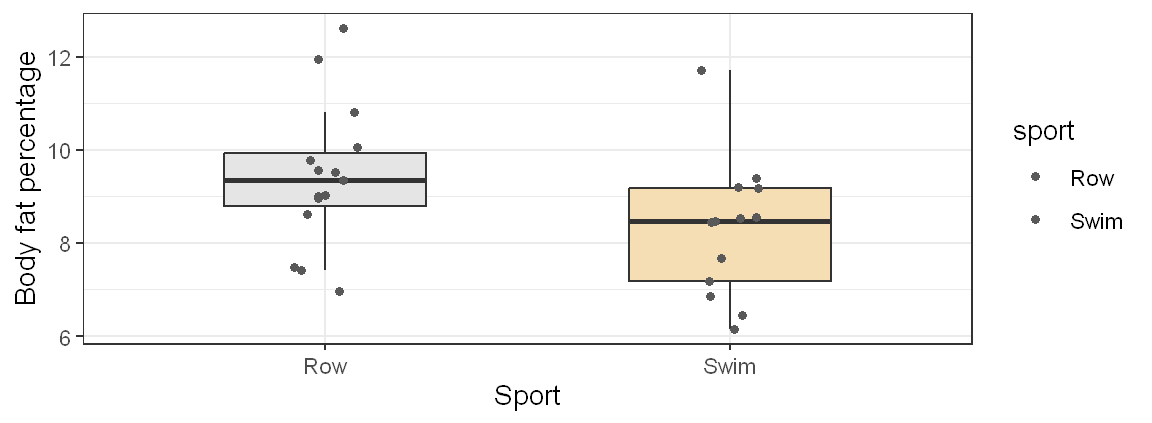

In [8]:
#| echo: false
#| fig-cap: "Body fat percentage by sport for the 28 male rowers and swimmers. Each dot is one athlete, moved sideways a little to avoid overlap. Boxes show the quartiles and the median, and whiskers reach the most extreme values within 1.5 times the interquartile range. Three rowers (6.96, 11.95 and 12.61) lie beyond the whiskers."
#| fig-pos: H
# Figure 1: boxplots with every athlete shown as a dot. The dots are
# moved sideways a little so that they do not overlap.
options(repr.plot.width = 6.4, repr.plot.height = 2.35)
boxplot_fig <- dat %>%
  ggplot(aes(x = sport, y = Bfat, fill = sport)) +
  geom_boxplot(width = 0.5, outlier.shape = NA, show.legend = FALSE) +
  geom_point(
    position = position_jitter(width = 0.08, height = 0, seed = 1),
    size = 1.3, colour = "grey35") +
  scale_fill_manual(values = c("grey90", "wheat")) +
  labs(x = "Sport", y = "Body fat percentage") +
  theme_bw(base_size = 11)
boxplot_fig

## 3. Formal data analysis

### 3.1.two-sample t-test

### 3.2. Wilcoxon rank-sum test

### 3.3. permutation test

### 3.4. Comparison of the three analyses

In [9]:
#| echo: false
# Table 2: the three analyses side by side
comparison <- tibble(
  Method = c("Welch t-test", "Wilcoxon rank-sum",
    "Permutation (mean difference)"),
  Statistic = c(
    sprintf("t = %.2f (df = %.2f)",
      welch_tidy$statistic, welch_tidy$parameter),
    sprintf("W = %d", as.integer(wilcox_tidy$statistic)),
    sprintf("mean difference = %.2f", observed_diff)),
  `p-value` = sprintf("%.3f",
    c(welch_tidy$p.value, wilcox_tidy$p.value, perm_p)))
report_table(comparison,
  "Table 2. Results of the three tests (two-sided, 28 athletes).")

**Table 2. Results of the three tests (two-sided, 28 athletes).**

| Method | Statistic | p-value |
| --- | --- | --- |
| Welch t-test | t = 1.94 (df = 25.76) | 0.064 |
| Wilcoxon rank-sum | W = 144 | 0.033 |
| Permutation (mean difference) | mean difference = 1.11 | 0.065 |

### 3.5. Assumption checks

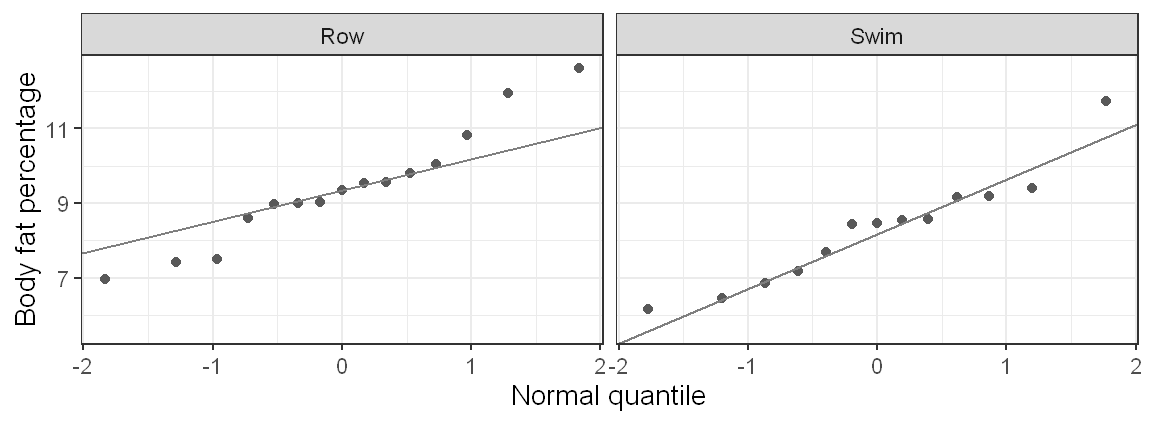

In [10]:
#| echo: false
#| fig-cap: "Normal Q-Q plots of body fat percentage for rowers (left) and swimmers (right). Points close to the line indicate approximately normal data."
#| fig-pos: H
# Figure 2: normal Q-Q plot for each group
options(repr.plot.width = 6.4, repr.plot.height = 2.35)
qq_fig <- dat %>%
  ggplot(aes(sample = Bfat)) +
  stat_qq(colour = "grey35") +
  stat_qq_line(colour = "grey50") +
  facet_wrap(~ sport) +
  labs(x = "Normal quantile", y = "Body fat percentage") +
  theme_bw(base_size = 11)
qq_fig

## 4. Conclusions and discussion

## References

Cook, R. D., and Weisberg, S. (1994). *An Introduction to Regression Graphics*. John Wiley & Sons, New York. Source of the `ais` data as listed on the `SkewHyperbolic` help page (via the package `sn`).

Telford, R. D., and Cunningham, R. B. (1991). Sex, sport and body-size dependency of hematology in highly trained athletes. *Medicine and Science in Sports and Exercise*, 23, 788-794. Cited on the `FPDclustering` help page for what appears to be the same data.


\clearpage
\pagenumbering{roman}

# Appendix A. R code

```r
# Setup: packages and display options
library(tidyverse)
library(broom)
library(SkewHyperbolic)
options(width = 64, repr.plot.res = 180)

# Helper: print a small data frame as a table in the report
report_table <- function(data, caption) {
  header <- paste(names(data), collapse = " | ")
  rule <- paste(rep("---", ncol(data)), collapse = " | ")
  rows <- apply(data, 1, paste, collapse = " | ")
  markdown <- paste(c(paste0("**", caption, "**"), "",
    paste0("| ", header, " |"), paste0("| ", rule, " |"),
    paste0("| ", rows, " |")), collapse = "\n")
  IRdisplay::display_markdown(markdown)
}

# Data: the 202 athletes in the ais data frame. Keep the 28 men who
# row or swim.
data(ais, package = "SkewHyperbolic")
dat <- ais %>%
  filter(sex == "male", sport %in% c("Row", "Swim")) %>%
  droplevels()
stopifnot(nrow(dat) == 28, !anyNA(dat),
  levels(dat$sport) == c("Row", "Swim"))

# Body fat percentage of each group
bf_row <- dat %>% filter(sport == "Row") %>% pull(Bfat)
bf_swim <- dat %>% filter(sport == "Swim") %>% pull(Bfat)

# Summary statistics for each sport (Table 1)
descriptive <- dat %>%
  group_by(sport) %>%
  summarize(N = n(), Mean = mean(Bfat), SD = sd(Bfat),
    Median = median(Bfat), IQR = IQR(Bfat),
    Min = min(Bfat), Max = max(Bfat)) %>%
  rename(Sport = sport)

# Difference in sample means, Row minus Swim
observed_diff <- mean(bf_row) - mean(bf_swim)

# Welch two-sample t-test and Wilcoxon rank-sum test (both two-sided)
welch <- t.test(Bfat ~ sport, data = dat)
wilcox <- wilcox.test(Bfat ~ sport, data = dat)

# tidy() turns each test result into a one-row table
welch_tidy <- tidy(welch)
wilcox_tidy <- tidy(wilcox)

# Rank-sum quantities quoted in Section 3.2
row_rank_sum <- dat %>%
  mutate(bfat_rank = rank(Bfat)) %>%
  filter(sport == "Row") %>%
  summarize(total = sum(bfat_rank)) %>%
  pull(total)
expected_rank_sum <- 15 * (28 + 1) / 2
prob_row_higher <- wilcox_tidy$statistic / (15 * 13)

# Permutation test, following the steps in the lecture slides.
# There are about 37 million ways to split the 28 values into groups
# of 15 and 13, so we use a random sample of 49,999 of them.
set.seed(20261114)
n_perm <- 49999

permuted_diff <- replicate(n_perm, {
  # Rearrange the 28 values, split them into 15 and 13, and
  # compute T, the difference in the two sample means
  shuffled <- sample(dat$Bfat)
  mean(shuffled[dat$sport == "Row"]) -
    mean(shuffled[dat$sport == "Swim"])
})

# Count the rearrangements at least as extreme as the observed one.
# The +1 counts the observed arrangement itself.
extremes <- sum(abs(permuted_diff) >= abs(observed_diff))
perm_p <- (extremes + 1) / (n_perm + 1)
perm_se <- sqrt(perm_p * (1 - perm_p) / (n_perm + 1))

permutation <- data.frame(observed_diff, n_perm, seed = 20261114,
  possible_splits = choose(28, 15), extremes,
  p_value = perm_p, monte_carlo_se = perm_se)

# Checks used in Section 3.5
shapiro_row <- shapiro.test(bf_row)
shapiro_swim <- shapiro.test(bf_swim)
variance_test <- var.test(Bfat ~ sport, data = dat)
sd_ratio <- sd(bf_row) / sd(bf_swim)

# Values beyond the boxplot whiskers (marked in Figure 1)
outliers <- dat %>%
  group_by(sport) %>%
  filter(Bfat %in% boxplot.stats(Bfat)$out) %>%
  ungroup() %>%
  select(sport, Bfat) %>%
  arrange(sport, Bfat) %>%
  as.data.frame()

# Table 1: round the summary statistics and print them as a table
table1 <- descriptive %>%
  mutate(across(Mean:Max, ~ sprintf("%.2f", .x)))
report_table(table1,
  "Table 1. Body fat percentage (%) by sport, male athletes.")

# Figure 1: boxplots with every athlete shown as a dot. The dots are
# moved sideways a little so that they do not overlap.
options(repr.plot.width = 6.4, repr.plot.height = 2.35)
boxplot_fig <- dat %>%
  ggplot(aes(x = sport, y = Bfat, fill = sport)) +
  geom_boxplot(width = 0.5, outlier.shape = NA, show.legend = FALSE) +
  geom_point(
    position = position_jitter(width = 0.08, height = 0, seed = 1),
    size = 1.3, colour = "grey35") +
  scale_fill_manual(values = c("grey90", "wheat")) +
  labs(x = "Sport", y = "Body fat percentage") +
  theme_bw(base_size = 11)
boxplot_fig

# Table 2: the three analyses side by side
comparison <- tibble(
  Method = c("Welch t-test", "Wilcoxon rank-sum",
    "Permutation (mean difference)"),
  Statistic = c(
    sprintf("t = %.2f (df = %.2f)",
      welch_tidy$statistic, welch_tidy$parameter),
    sprintf("W = %d", as.integer(wilcox_tidy$statistic)),
    sprintf("mean difference = %.2f", observed_diff)),
  `p-value` = sprintf("%.3f",
    c(welch_tidy$p.value, wilcox_tidy$p.value, perm_p)))
report_table(comparison,
  "Table 2. Results of the three tests (two-sided, 28 athletes).")

# Figure 2: normal Q-Q plot for each group
options(repr.plot.width = 6.4, repr.plot.height = 2.35)
qq_fig <- dat %>%
  ggplot(aes(sample = Bfat)) +
  stat_qq(colour = "grey35") +
  stat_qq_line(colour = "grey50") +
  facet_wrap(~ sport) +
  labs(x = "Normal quantile", y = "Body fat percentage") +
  theme_bw(base_size = 11)
qq_fig

# Appendix B: dataset structure, group counts and missing values
str(ais)
print(count(ais, sex))
print(count(dat, sport))
print(colSums(is.na(dat)))
print(dat)

# Appendix B: summary statistics
print(as.data.frame(descriptive))
print(c(observed_difference = observed_diff))

# Appendix B: Welch t-test, Wilcoxon rank-sum test, rank-sum quantities
print(welch)
print(wilcox)
print(c(row_rank_sum = row_rank_sum,
  expected_rank_sum = expected_rank_sum,
  prob_row_higher = prob_row_higher))

# Appendix B: permutation test
print(permutation)

# Appendix B: normality, variance and outlier checks
print(shapiro_row)
print(shapiro_swim)
print(variance_test)
print(c(sd_ratio = sd_ratio))
print(outliers)

# Appendix C: histogram of the shuffled mean differences, and the
# computing environment
options(repr.plot.width = 6.4, repr.plot.height = 2.6)
permutation_fig <- tibble(permuted_diff = permuted_diff) %>%
  ggplot(aes(x = permuted_diff)) +
  geom_histogram(bins = 45, fill = "grey85", colour = "white") +
  geom_vline(xintercept = c(-observed_diff, observed_diff),
    linewidth = 0.8, colour = "grey20") +
  labs(x = "Permuted mean difference (percentage points)",
    y = "Frequency") +
  theme_bw(base_size = 11)
print(permutation_fig)

print(R.version.string)
print(as.character(packageVersion("SkewHyperbolic")))
print(as.character(packageVersion("tidyverse")))
print(RNGkind())
```

\clearpage

# Appendix B. Raw R output

\leavevmode\par

### Dataset structure, group counts and missing values

In [11]:
#| echo: false
# Appendix B: dataset structure, group counts and missing values
str(ais)
print(count(ais, sex))
print(count(dat, sport))
print(colSums(is.na(dat)))
print(dat)

'data.frame':	202 obs. of  13 variables:
 $ sex  : Factor w/ 2 levels "female","male": 1 1 1 1 1 1 1 1 1 1 ...
 $ sport: Factor w/ 10 levels "B_Ball","Field",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ rcc  : num  3.96 4.41 4.14 4.11 4.45 4.1 4.31 4.42 4.3 4.51 ...
 $ wcc  : num  7.5 8.3 5 5.3 6.8 4.4 5.3 5.7 8.9 4.4 ...
 $ Hc   : num  37.5 38.2 36.4 37.3 41.5 37.4 39.6 39.9 41.1 41.6 ...
 $ Hg   : num  12.3 12.7 11.6 12.6 14 12.5 12.8 13.2 13.5 12.7 ...
 $ Fe   : num  60 68 21 69 29 42 73 44 41 44 ...
 $ bmi  : num  20.6 20.7 21.9 21.9 19 ...
 $ ssf  : num  109.1 102.8 104.6 126.4 80.3 ...
 $ Bfat : num  19.8 21.3 19.9 23.7 17.6 ...
 $ lbm  : num  63.3 58.5 55.4 57.2 53.2 ...
 $ Ht   : num  196 190 178 185 185 ...
 $ Wt   : num  78.9 74.4 69.1 74.9 64.6 63.7 75.2 62.3 66.5 62.9 ...
     sex   n
1 female 100
2   male 102
  sport  n
1   Row 15
2  Swim 13
  sex sport   rcc   wcc    Hc    Hg    Fe   bmi   ssf  Bfat 
    0     0     0     0     0     0     0     0     0     0 
  lbm    Ht    Wt 
    0 

### Summary statistics

In [12]:
#| echo: false
# Appendix B: summary statistics
print(as.data.frame(descriptive))
print(c(observed_difference = observed_diff))

  Sport  N     Mean       SD Median  IQR  Min   Max
1   Row 15 9.409333 1.559306   9.36 1.13 6.96 12.61
2  Swim 13 8.296154 1.480487   8.47 1.98 6.16 11.72
observed_difference 
           1.113179 


### Welch t-test, Wilcoxon rank-sum test and rank sums

In [13]:
#| echo: false
# Appendix B: Welch t-test, Wilcoxon rank-sum test, rank-sum quantities
print(welch)
print(wilcox)
print(c(row_rank_sum = row_rank_sum,
  expected_rank_sum = expected_rank_sum,
  prob_row_higher = prob_row_higher))


	Welch Two Sample t-test

data:  Bfat by sport
t = 1.9357, df = 25.758, p-value = 0.06395
alternative hypothesis: true difference in means between group Row and group Swim is not equal to 0
95 percent confidence interval:
 -0.06942239  2.29578136
sample estimates:
 mean in group Row mean in group Swim 
          9.409333           8.296154 


	Wilcoxon rank sum exact test

data:  Bfat by sport
W = 144, p-value = 0.0325
alternative hypothesis: true location shift is not equal to 0

     row_rank_sum expected_rank_sum prob_row_higher.W 
      264.0000000       217.5000000         0.7384615 


### Monte Carlo permutation test

In [14]:
#| echo: false
# Appendix B: permutation test
print(permutation)

  observed_diff n_perm     seed possible_splits extremes
1      1.113179  49999 20261114        37442160     3270
  p_value monte_carlo_se
1 0.06542    0.001105805


### Normality, variance and outlier checks

In [15]:
#| echo: false
# Appendix B: normality, variance and outlier checks
print(shapiro_row)
print(shapiro_swim)
print(variance_test)
print(c(sd_ratio = sd_ratio))
print(outliers)


	Shapiro-Wilk normality test

data:  bf_row
W = 0.95042, p-value = 0.5311


	Shapiro-Wilk normality test

data:  bf_swim
W = 0.93585, p-value = 0.4054


	F test to compare two variances

data:  Bfat by sport
F = 1.1093, num df = 14, denom df = 12, p-value = 0.8664
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 0.3459881 3.3835709
sample estimates:
ratio of variances 
          1.109311 

sd_ratio 
1.053238 
  sport  Bfat
1   Row  6.96
2   Row 11.95
3   Row 12.61


\clearpage

# Appendix C. Permutation distribution and computing environment

[1] "R version 4.6.1 (2026-06-24 ucrt)"
[1] "0.4.2"
[1] "2.0.0"
[1] "Mersenne-Twister" "Inversion"        "Rejection"       


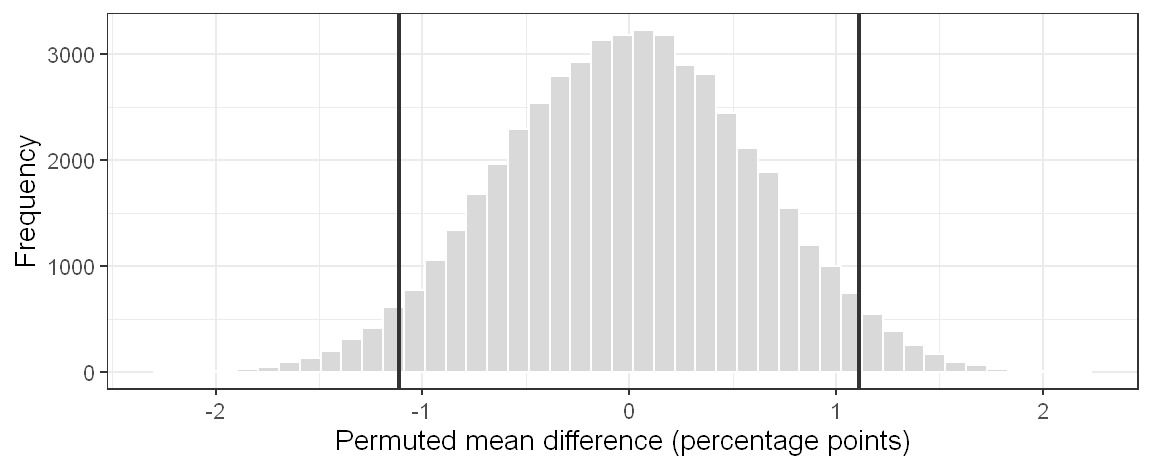

In [16]:
#| echo: false
# Appendix C: histogram of the shuffled mean differences, and the
# computing environment
options(repr.plot.width = 6.4, repr.plot.height = 2.6)
permutation_fig <- tibble(permuted_diff = permuted_diff) %>%
  ggplot(aes(x = permuted_diff)) +
  geom_histogram(bins = 45, fill = "grey85", colour = "white") +
  geom_vline(xintercept = c(-observed_diff, observed_diff),
    linewidth = 0.8, colour = "grey20") +
  labs(x = "Permuted mean difference (percentage points)",
    y = "Frequency") +
  theme_bw(base_size = 11)
print(permutation_fig)

print(R.version.string)
print(as.character(packageVersion("SkewHyperbolic")))
print(as.character(packageVersion("tidyverse")))
print(RNGkind())